# 01 - Download macro data

Download raw FRED series, align them to monthly frequency and save to `data/raw/macro_monthly_raw.csv`. No transformations here (see notebook 02).

## 1. Imports and key loading

In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred

ENV_PATH = find_dotenv(usecwd=True)
load_dotenv(ENV_PATH)
fred = Fred(api_key=os.environ["FRED_API_KEY"])

PROJECT_ROOT = Path(ENV_PATH).parent
START, END = "1998-01-01", "2023-12-31"

## 2. Series dictionary

In [3]:
SERIES = {
    "cpi": "CPIAUCSL",
    "cpi_core": "CPILFESL",
    "oil": "DCOILWTICO",  # daily
    "gas": "GASREGW",  # weekly
    "exp": "MICH",
    "ppi": "PPIACO",
    "housing": "HOUST",
    "payems": "PAYEMS",
}

## 3. Download series and metadata

In [4]:
raw = {}
meta_rows = []
for name, series_id in SERIES.items():
    raw[name] = fred.get_series(
        series_id, observation_start=START, observation_end=END
    )
    info = fred.get_series_info(series_id)
    meta_rows.append({
        "name": name,
        "id": info["id"],
        "title": info["title"],
        "frequency": info["frequency"],
        "units": info["units"],
        "seasonal_adjustment": info["seasonal_adjustment"],
        "observation_start": info["observation_start"],
    })

metadata = pd.DataFrame(meta_rows).set_index("name")
metadata

,id,title,frequency,units,seasonal_adjustment,observation_start
name,,,,,,
cpi,CPIAUCSL,Consumer Price Index for All Urban Consumers: ...,Monthly,Index 1982-1984=100,Seasonally Adjusted,1947-01-01
cpi_core,CPILFESL,Consumer Price Index for All Urban Consumers: ...,Monthly,Index 1982-1984=100,Seasonally Adjusted,1957-01-01
oil,DCOILWTICO,Crude Oil Prices: West Texas Intermediate (WTI...,Daily,Dollars per Barrel,Not Seasonally Adjusted,1986-01-02
gas,GASREGW,US Regular All Formulations Gas Price,"Weekly, Ending Monday",Dollars per Gallon,Not Seasonally Adjusted,1990-08-20
exp,MICH,University of Michigan: Inflation Expectation,Monthly,Percent,Not Seasonally Adjusted,1978-01-01
ppi,PPIACO,Producer Price Index by Commodity: All Commodi...,Monthly,Index 1982=100,Not Seasonally Adjusted,1913-01-01
housing,HOUST,New Privately-Owned Housing Units Started: Tot...,Monthly,Thousands of Units,Seasonally Adjusted Annual Rate,1959-01-01
payems,PAYEMS,"All Employees, Total Nonfarm",Monthly,Thousands of Persons,Seasonally Adjusted,1939-01-01


## 4. Coverage report

In [5]:
report = pd.DataFrame({
    name: {
        "first_date": s.index.min().date(),
        "last_date": s.index.max().date(),
        "n_obs": len(s),
        "missing": s.isna().sum(),
    }
    for name, s in raw.items()
}).T
report

,first_date,last_date,n_obs,missing
cpi,1998-01-01,2023-12-01,312,0
cpi_core,1998-01-01,2023-12-01,312,0
oil,1998-01-01,2023-12-29,6782,746
gas,1998-01-05,2023-12-25,1356,0
exp,1998-01-01,2023-12-01,312,0
ppi,1998-01-01,2023-12-01,312,0
housing,1998-01-01,2023-12-01,312,0
payems,1998-01-01,2023-12-01,312,0


## 5. Convert to monthly

Monthly series are kept as-is on a month-start index. Daily and weekly series (oil, gas) get both a monthly mean and a last-value column.

In [6]:
HIGH_FREQ = ["oil", "gas"]

monthly = {}
for name, s in raw.items():
    resampled = s.resample("MS")
    if name in HIGH_FREQ:
        monthly[f"{name}_mean"] = resampled.mean()
        monthly[f"{name}_last"] = resampled.last()
    else:
        monthly[name] = resampled.mean()

df = pd.DataFrame(monthly)
df.index.name = "date"
df.head()

,cpi,cpi_core,oil_mean,oil_last,gas_mean,gas_last,exp,ppi,housing,payems
date,,,,,,,,,,
1998-01-01,162.0,171.6,16.696250,17.21,1.08625,1.066,2.3,125.4,1525.0,124806.0
1998-02-01,162.0,171.9,16.061176,15.44,1.04900,1.044,2.4,125.0,1584.0,125017.0
1998-03-01,162.0,172.2,15.125714,15.75,1.01680,1.030,2.5,124.7,1567.0,125165.0
1998-04-01,162.2,172.5,15.353810,15.56,1.03025,1.040,2.4,124.9,1540.0,125445.0
1998-05-01,162.6,172.9,14.923529,15.21,1.06350,1.070,2.6,125.1,1536.0,125845.0


## 6. Plot each series

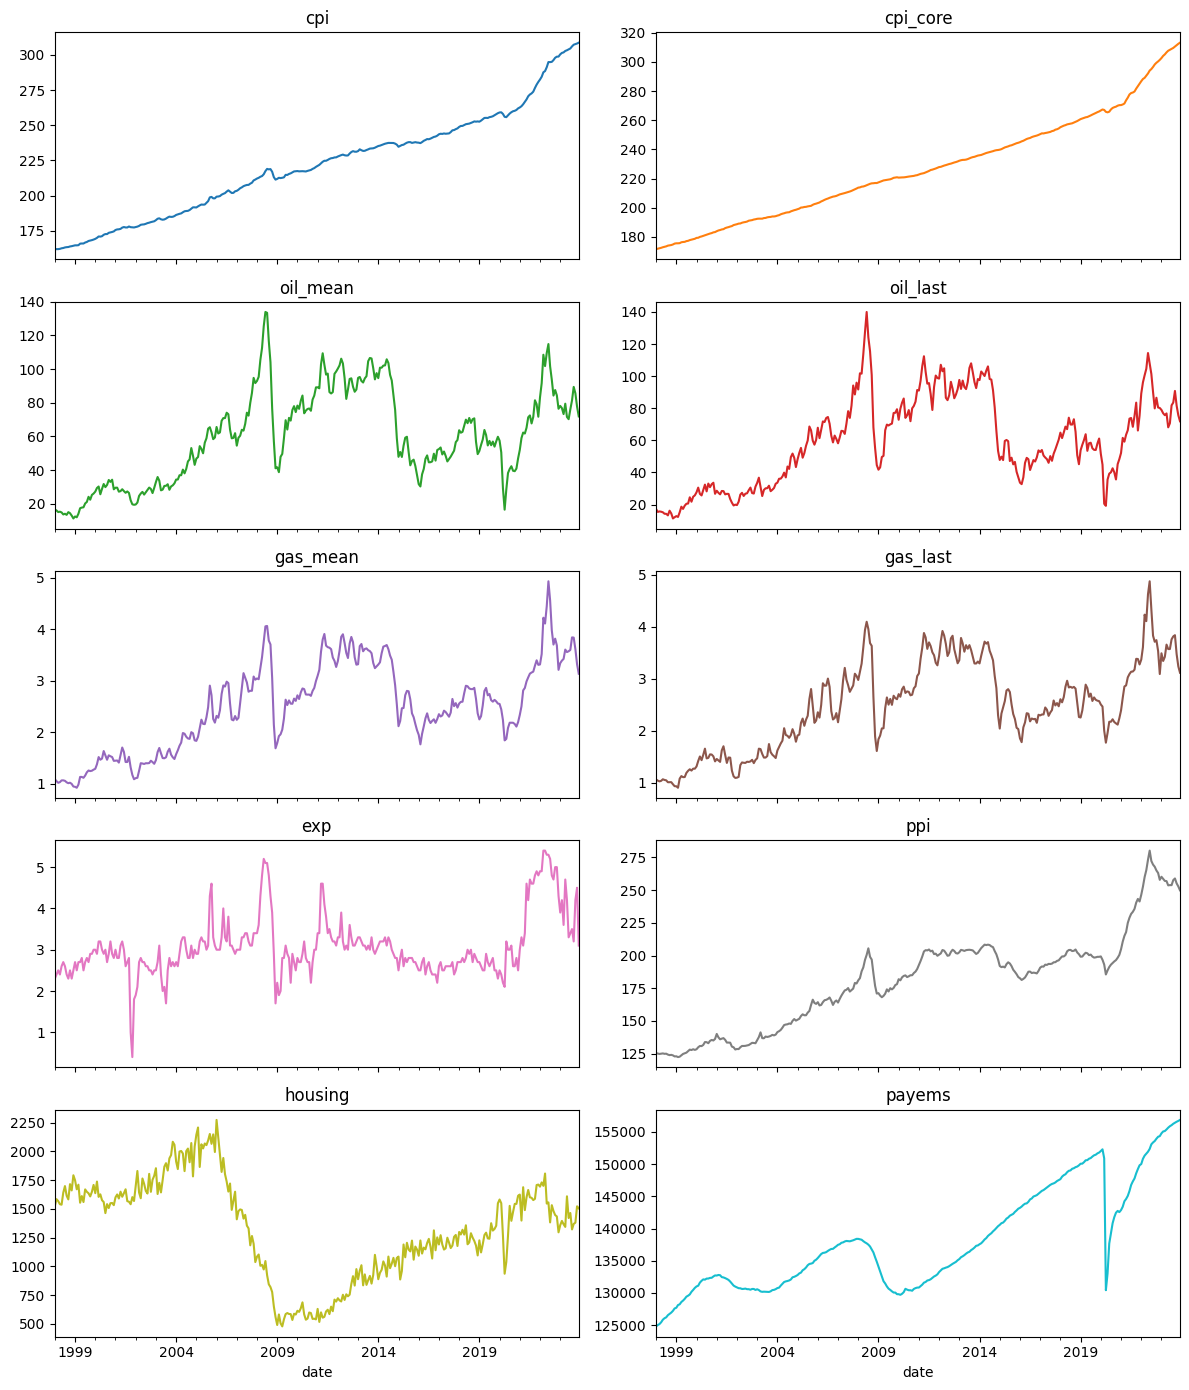

In [7]:
axes = df.plot(
    subplots=True, layout=(5, 2), figsize=(12, 14), sharex=True, legend=False
)
for ax, col in zip(axes.flat, df.columns):
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 7. Check the index

In [8]:
expected = pd.date_range("1998-01-01", "2023-12-01", freq="MS")
assert df.index.is_unique, "duplicate months in index"
assert df.index.equals(expected), "index does not run 1998-01 to 2023-12"
print(f"OK: {len(df)} months, {df.index[0]:%Y-%m} to {df.index[-1]:%Y-%m}")

OK: 312 months, 1998-01 to 2023-12


## 8. Save

In [9]:
out_path = PROJECT_ROOT / "data" / "raw" / "macro_monthly_raw.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(out_path)
print(f"Saved {df.shape} to {out_path.relative_to(PROJECT_ROOT)}")

Saved (312, 10) to raw_data/macro_monthly_raw.csv
